In [84]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

All libraries imported successfully!
Pandas version: 3.1.0
NumPy version: 2.5.4


In [85]:
import pandas as pd

df = pd.read_csv("Customer Churn.csv")
print(df.head())
print(df.shape)
df.info()

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

#Replacing blanks with 0 in TotalCharges column as Tenure was 0

In [86]:
df["TotalCharges"] = df["TotalCharges"].replace(" ", "0")
df["TotalCharges"] = df["TotalCharges"].astype("float")

In [87]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

#Checking missing val : No missing val +nt

In [88]:
df.isnull().sum().sum()

np.int64(0)

#Statistical val

In [89]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


#Duplicates checking : No duplicates +nt

In [90]:
df["customerID"].duplicated().sum()

np.int64(0)

#Function def create to change 1/0 to yes and no of Senior citizen col to make it simpler to understand

In [91]:
def conv(value):
   if value == 1:
       return "yes"
   else:
       return "no"

df["SeniorCitizen"] = df["SeniorCitizen"].apply(conv)

In [92]:
df.head(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,no,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,no,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,no,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,no,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,no,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


#Analysis part :Churn count (yes = left , no = stayed)

In [93]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

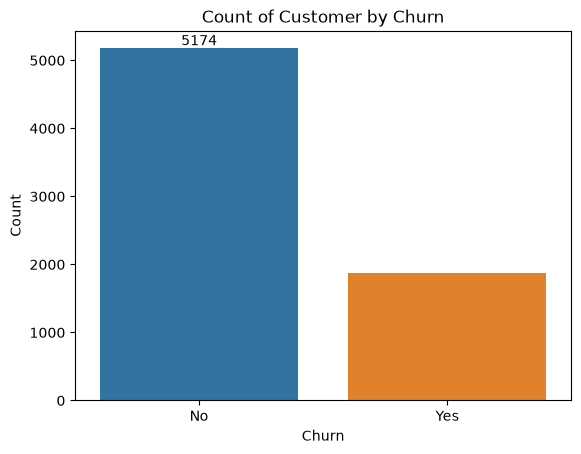

In [94]:
ax = sns.countplot(data = df, x = "Churn" , hue = "Churn")
ax.bar_label(ax.containers[0])
plt.title("Count of Customer by Churn")
plt.xlabel("Churn")
plt.ylabel("Count")
plt.show()

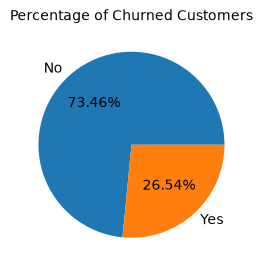

In [95]:
plt.figure(figsize = (3,4))
gb = df.groupby("Churn").agg({'Churn' : "count"})
plt.pie(gb["Churn"], labels = gb.index , autopct = "%1.2f%%")
plt.title("Percentage of Churned Customers", fontsize = 10)
plt.show()

#From the above pie chart we conclude that 26.54% people have churned out
#Explore the reason behind it 

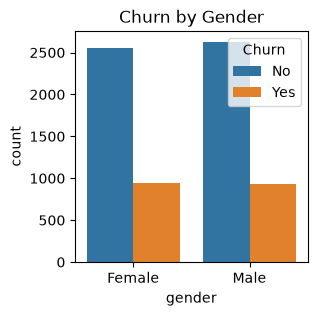

In [96]:
plt.figure(figsize = (3,3))
sns.countplot(data = df, x = "gender", hue = "Churn")
plt.title("Churn by Gender")
plt.show()

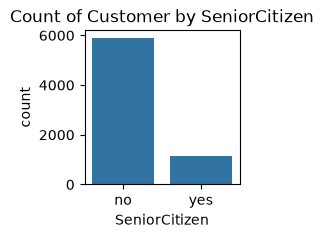

In [97]:
plt.figure(figsize = (2,2))
sns.countplot(data = df, x = "SeniorCitizen")
plt.title("Count of Customer by SeniorCitizen")
plt.show()

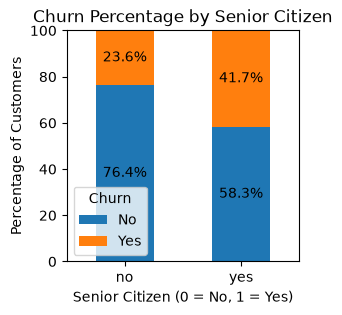

In [98]:
# Calculate percentage of churn for each SeniorCitizen group
churn_percentage = pd.crosstab( df["SeniorCitizen"], df["Churn"], normalize="index")* 100

# Create a 100% stacked bar graph
ax = churn_percentage.plot( kind="bar", stacked=True, figsize=(3,3))

# Add percentage values inside the bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", label_type="center")

plt.title("Churn Percentage by Senior Citizen")
plt.xlabel("Senior Citizen (0 = No, 1 = Yes)")
plt.ylabel("Percentage of Customers")
plt.legend(title="Churn")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.show()

#Comparatively a greater percentage of people have churned out in senior citizen category

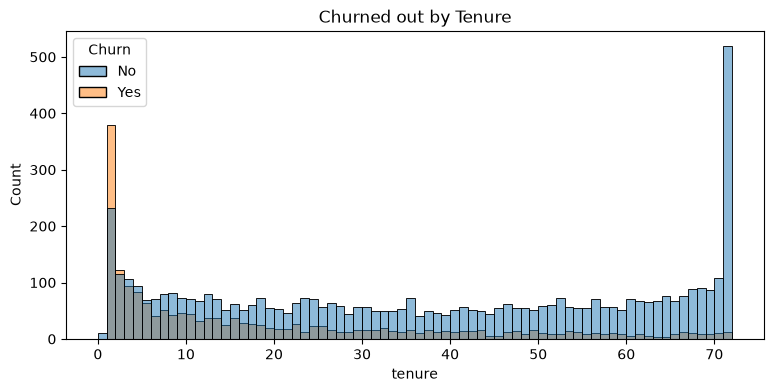

In [99]:
plt.figure(figsize = (9,4))
sns.histplot(data = df, x = "tenure",bins = 72, hue = "Churn")
plt.title("Churned out by Tenure")
plt.show()

#People who have used our services for long time have stayed,but people who have used the services gor 1 or 2 mnths have churned out

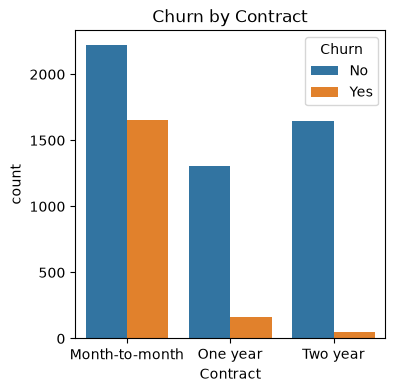

In [100]:
plt.figure(figsize = (4,4))
sns.countplot(data = df, x = "Contract", hue = "Churn")
plt.title("Churn by Contract")
plt.show()

#People who have contract for mnth-mnth have been churned out more than people who have contract for one or two yrs 

In [101]:
df.columns.values
array = (['customerID', 'gender', 'SeniorCitizen', 'Partner	Dependents', 'tenure', 'PhoneService', 'MultipleLines',	'InternetService',
         'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',	'Contract',	'PaperlessBilling', 
          'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'])


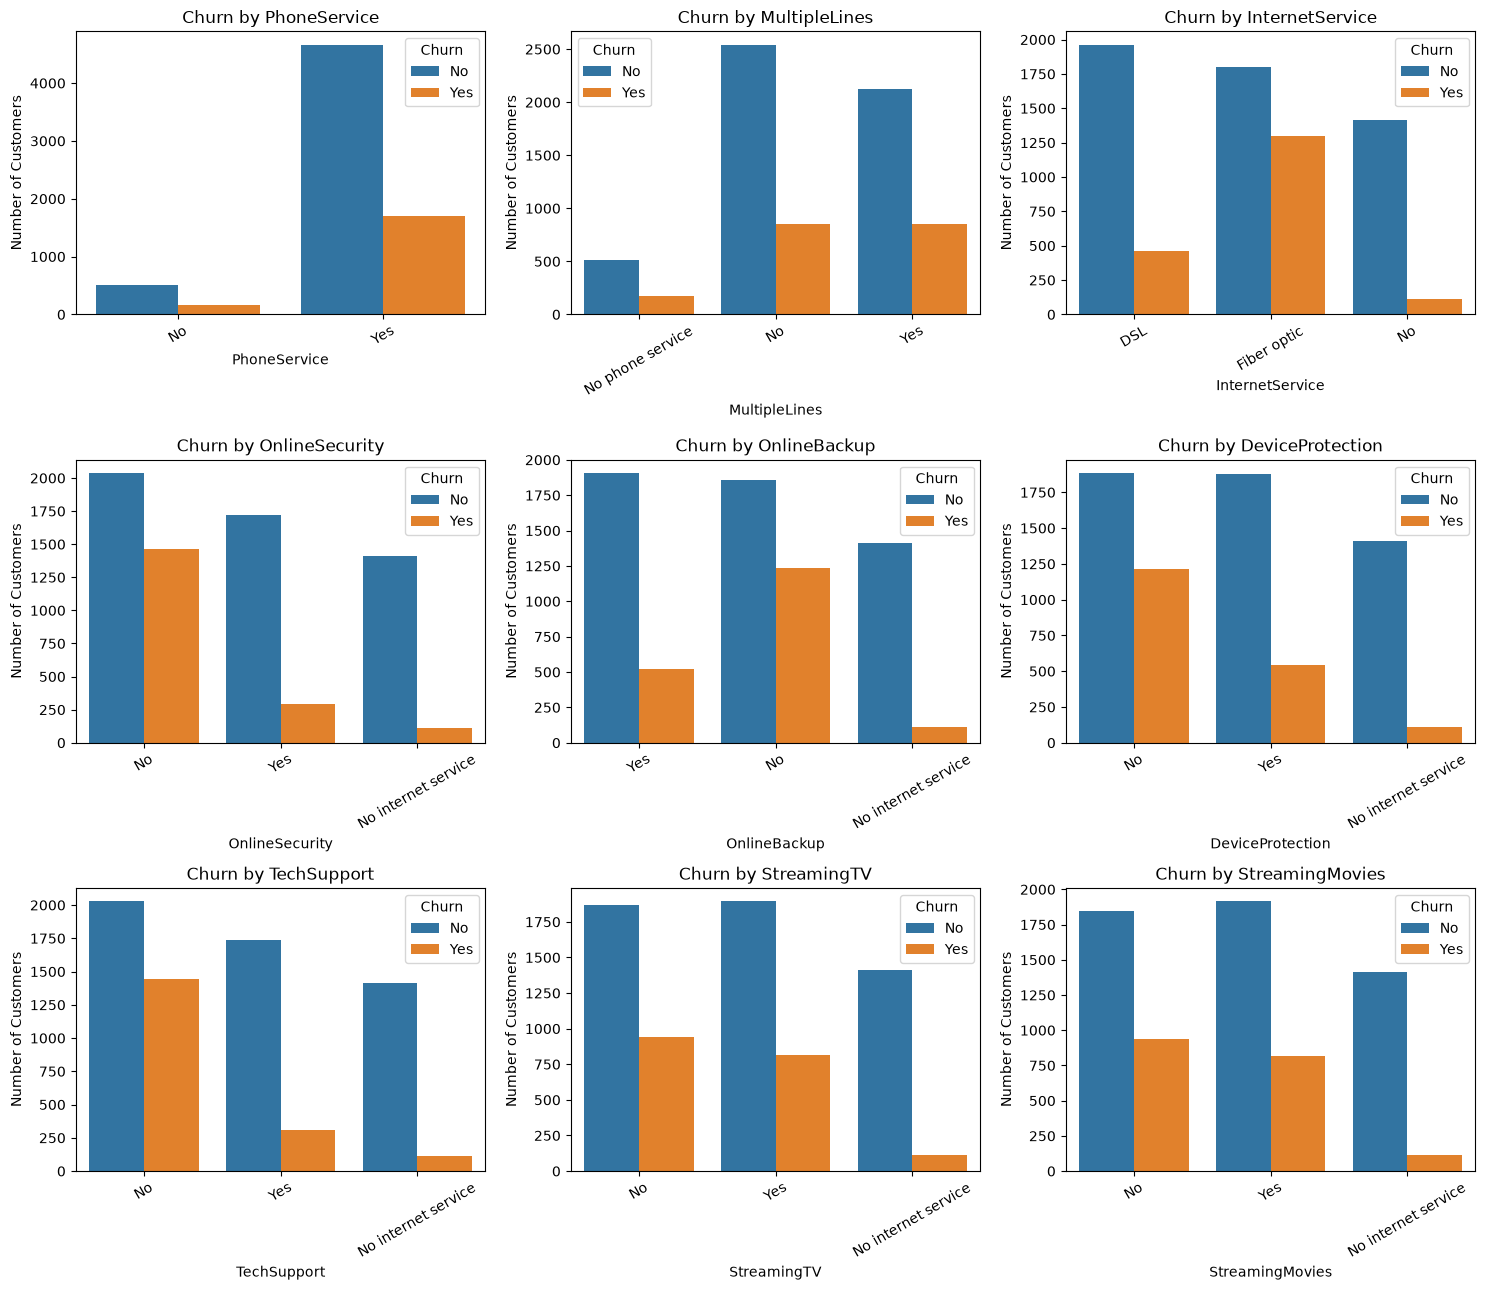

In [102]:
columns = [ "PhoneService", "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup","DeviceProtection",
            "TechSupport", "StreamingTV", "StreamingMovies"]

plt.figure(figsize=(15, 13))

for i, col in enumerate(columns, 1):
    plt.subplot(3, 3, i)

    sns.countplot(data=df, x=col, hue="Churn")

    plt.title(f"Churn by {col}")
    plt.xlabel(col)
    plt.ylabel("Number of Customers")
    plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

#Customers without Online Security and Tech Support show noticeably higher churn compared to customers who have these services.
Fiber optic users also have a higher number of churned customers than DSL users. Customers without Device Protection 
and Online Backup also show higher churn counts. Overall, additional support and security services may help improve customer retention.

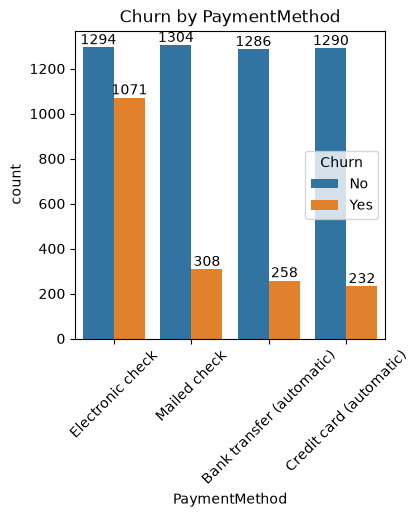

In [103]:
plt.figure(figsize = (4,4))
ax = sns.countplot(data = df, x = "PaymentMethod", hue = "Churn")
ax.bar_label(ax.containers[0])
ax.bar_label(ax.containers[1])
plt.title("Churn by PaymentMethod")
plt.xticks(rotation = 45)
plt.show()

#Customer are likely to churn when he is using electronic check as paymnet 